In [1]:
!pip install -q pandas numpy networkx python-louvain scikit-learn matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

import community as community_louvain

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [3]:
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

edges = pd.read_csv(filename)

print(edges.shape)

edges.head()

Saving musae_git_edges.csv to musae_git_edges.csv
(289003, 2)


,id_1,id_2
0,0,23977
1,1,34526
2,1,2370
3,1,14683
4,1,29982


In [4]:
edges = edges.rename(columns={
    "id_1": "source",
    "id_2": "target"
})

In [5]:
G = nx.from_pandas_edgelist(
    edges,
    source="source",
    target="target",
    create_using=nx.Graph()
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 37700
Edges: 289003


In [6]:
activity = pd.Series(
    dict(G.degree()),
    name="activity"
)

In [7]:
popularity = activity.rename(
    "popularity"
)

In [8]:
pagerank = pd.Series(
    nx.pagerank(G),
    name="pagerank"
)

In [9]:
betweenness = pd.Series(
    nx.betweenness_centrality(
        G,
        k=500,
        seed=42
    ),
    name="betweenness"
)

In [10]:
clustering = pd.Series(
    nx.clustering(G),
    name="clustering_coefficient"
)

In [12]:
!pip uninstall -y community
!pip install -U python-louvain

Found existing installation: community 1.0.0b1
Uninstalling community-1.0.0b1:
  Successfully uninstalled community-1.0.0b1


In [13]:
import community.community_louvain as community_louvain

In [14]:
partition = community_louvain.best_partition(G)

community_id = pd.Series(
    partition,
    name="community_id"
)

print(
    "Number of communities:",
    community_id.nunique()
)

Number of communities: 39


In [15]:
github_features = pd.concat(
    [
        activity,
        popularity,
        pagerank,
        betweenness,
        clustering,
        community_id
    ],
    axis=1
)

github_features.index.name = "userID"

github_features = github_features.fillna(0)

github_features.head()

,activity,popularity,pagerank,betweenness,clustering_coefficient,community_id
userID,,,,,,
0,1,1,0.000005,0.000000e+00,0.000000,0
23977,32,32,0.000052,7.251747e-05,0.098790,0
1,8,8,0.000017,4.146232e-07,0.178571,1
34526,2,2,0.000007,1.572581e-07,0.000000,0
2370,40,40,0.000052,1.244909e-05,0.176923,1


In [16]:
github_features.to_csv(
    "github_behavior_features.csv"
)

print("Saved github_behavior_features.csv")

Saved github_behavior_features.csv


In [17]:
files.download("github_behavior_features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
edge_set = set(
    tuple(sorted(edge))
    for edge in G.edges()
)

nodes = list(G.nodes())

In [19]:
def github_pair_features(source, target):

    neighbors_source = set(
        G.neighbors(source)
    )

    neighbors_target = set(
        G.neighbors(target)
    )

    common_neighbors = len(
        neighbors_source.intersection(
            neighbors_target
        )
    )

    union = len(
        neighbors_source.union(
            neighbors_target
        )
    )

    jaccard = (
        common_neighbors / union
        if union > 0 else 0
    )

    preferential_attachment = (
        G.degree(source) *
        G.degree(target)
    )

    adamic_adar = sum(
        1 / np.log(G.degree(n))
        for n in neighbors_source.intersection(
            neighbors_target
        )
        if G.degree(n) > 1
    )

    same_community = int(
        partition.get(source) ==
        partition.get(target)
    )

    return [
        G.degree(source),
        G.degree(target),

        pagerank.get(source, 0),
        pagerank.get(target, 0),

        betweenness.get(source, 0),
        betweenness.get(target, 0),

        clustering.get(source, 0),
        clustering.get(target, 0),

        common_neighbors,
        jaccard,

        preferential_attachment,
        adamic_adar,

        same_community
    ]

In [21]:
np.random.seed(42)

negative_edges = set()

target_count = len(positive_edges)

while len(negative_edges) < target_count:

    sources = np.random.choice(nodes, size=100000)
    targets = np.random.choice(nodes, size=100000)

    for source, target in zip(sources, targets):

        if source == target:
            continue

        edge = tuple(sorted((source, target)))

        if edge not in edge_set:
            negative_edges.add(edge)

        if len(negative_edges) >= target_count:
            break

negative_edges = list(negative_edges)

print("Positive:", len(positive_edges))
print("Negative:", len(negative_edges))

Positive: 289003
Negative: 289003


In [22]:
feature_names = [
    "source_degree",
    "target_degree",

    "source_pagerank",
    "target_pagerank",

    "source_betweenness",
    "target_betweenness",

    "source_clustering",
    "target_clustering",

    "common_neighbors",
    "jaccard",

    "preferential_attachment",
    "adamic_adar",

    "same_community"
]

In [23]:
X = []
y = []

for source, target in positive_edges:

    X.append(
        github_pair_features(source, target)
    )

    y.append(1)


for source, target in negative_edges:

    X.append(
        github_pair_features(source, target)
    )

    y.append(0)

In [24]:
X = pd.DataFrame(
    X,
    columns=feature_names
)

y = pd.Series(y)

print(X.shape)

(578006, 13)


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [26]:
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)

In [27]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(
    X_test
)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.9283316897631528
Precision: 0.9320315499249642
Recall: 0.9240497569246207
F1: 0.9280234911864613
ROC-AUC: 0.980380853016909


In [28]:
importance = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

importance

,feature,importance
10,preferential_attachment,0.170602
2,source_pagerank,0.165894
0,source_degree,0.140839
11,adamic_adar,0.110977
4,source_betweenness,0.091103
12,same_community,0.076601
6,source_clustering,0.043906
8,common_neighbors,0.041775
9,jaccard,0.038186
3,target_pagerank,0.035733


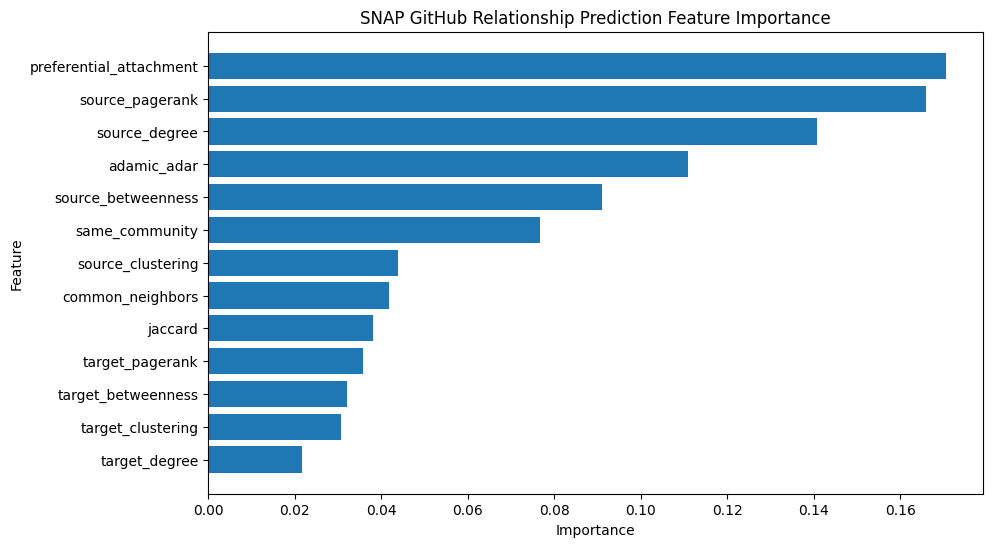

In [29]:
plt.figure(figsize=(10,6))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(
    "SNAP GitHub Relationship Prediction Feature Importance"
)

plt.gca().invert_yaxis()

plt.show()